In [ ]:
# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 2. LOAD DATASETS
transactions_raw = pd.read_csv(r"C:\Users\Syaza\Downloads\Dataset - transactions.csv")
leads_raw = pd.read_csv(r"C:\Users\Syaza\Downloads\Dataset - sourcing_leads.csv")

# Work on copies so raw data remains unchanged.
transactions = transactions_raw.copy()
leads = leads_raw.copy()

In [10]:
# 3. INITIAL DATA INSPECTION
print('TRANSACTIONS SHAPE:', transactions.shape)
print('LEADS SHAPE:', leads.shape)
print('\nTRANSACTIONS INFO')
transactions.info()
print('\nLEADS INFO')
leads.info()
print('\nTRANSACTIONS PREVIEW')
print(transactions.head())
print('\nLEADS PREVIEW')
print(leads.head())

TRANSACTIONS SHAPE: (1273, 7)
LEADS SHAPE: (10000, 9)

TRANSACTIONS INFO
<class 'pandas.DataFrame'>
RangeIndex: 1273 entries, 0 to 1272
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   transaction_id  1273 non-null   str  
 1   lead_id         1273 non-null   str  
 2   handover_date   1273 non-null   str  
 3   buy_price       1273 non-null   int64
 4   sell_price      1273 non-null   int64
 5   refurb_cost     1273 non-null   int64
 6   days_to_sell    1273 non-null   int64
dtypes: int64(4), str(3)
memory usage: 69.7 KB

LEADS INFO
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   lead_id                  10000 non-null  str  
 1   created_at               10000 non-null  str  
 2   channel                  10000 non-null  str  
 3   make                     

In [ ]:
# 4. DATA QUALITY AUDIT
print('\nMISSING VALUES - TRANSACTIONS')
print(transactions.isna().sum())
print('\nMISSING VALUES - LEADS')
print(leads.isna().sum())
print('\nFULL ROW DUPLICATES - TRANSACTIONS:', transactions.duplicated().sum())
print('FULL ROW DUPLICATES - LEADS:', leads.duplicated().sum())
print('\nDUPLICATE LEAD IDS - TRANSACTIONS:', transactions['lead_id'].duplicated().sum())
print('DUPLICATE LEAD IDS - LEADS:', leads['lead_id'].duplicated().sum())


MISSING VALUES - TRANSACTIONS
transaction_id    0
lead_id           0
handover_date     0
buy_price         0
sell_price        0
refurb_cost       0
days_to_sell      0
dtype: int64

MISSING VALUES - LEADS
lead_id                    0
created_at                 0
channel                    0
make                       0
model                      0
manufacture_year           0
mileage_km                 0
quoted_indicative_price    0
inspection_status          0
dtype: int64

FULL ROW DUPLICATES - TRANSACTIONS: 0
FULL ROW DUPLICATES - LEADS: 0

DUPLICATE LEAD IDS - TRANSACTIONS: 5
DUPLICATE LEAD IDS - LEADS: 0


In [ ]:
# 5. INVESTIGATE REPEATED TRANSACTION BUSINESS EVENTS
# transaction_id differs, so check whether the business-event fields repeat.
business_key = ['lead_id', 'handover_date', 'buy_price', 'sell_price', 'refurb_cost', 'days_to_sell']
repeated_events = transactions[transactions.duplicated(subset=business_key, keep=False)].sort_values('lead_id')
print('\nREPEATED BUSINESS EVENTS')
print(repeated_events.to_string(index=False))

# Keep the first copy of each repeated business event.
# This removes 5 repeated business records while retaining the original transaction_id of the first copy.
transactions = transactions.drop_duplicates(subset=business_key, keep='first').copy()
print('\nTRANSACTIONS AFTER BUSINESS-KEY DEDUPLICATION:', transactions.shape)


REPEATED BUSINESS EVENTS
transaction_id  lead_id handover_date  buy_price  sell_price  refurb_cost  days_to_sell
      TX-50331 LD-12262    2026-07-21      43500       49000          866            30
      TX-51269 LD-12262    2026-07-21      43500       49000          866            30
      TX-50411 LD-12765    2026-07-19      12400       14500          973            21
      TX-51270 LD-12765    2026-07-19      12400       14500          973            21
      TX-50724 LD-15098    2026-08-27       8000        8500         4311            75
      TX-51272 LD-15098    2026-08-27       8000        8500         4311            75
      TX-50800 LD-15848    2026-08-06      33200       37000         1178            19
      TX-51271 LD-15848    2026-08-06      33200       37000         1178            19
      TX-51083 LD-18412    2026-08-15      48100       53500         1328            32
      TX-51273 LD-18412    2026-08-15      48100       53500         1328            32

TRANS

In [ ]:
# 6. CONVERT DATE COLUMNS AND CHECK PARSING
transactions['handover_date'] = pd.to_datetime(transactions['handover_date'], errors='coerce')
leads['created_at'] = pd.to_datetime(leads['created_at'], errors='coerce')
print('Invalid handover dates:', transactions['handover_date'].isna().sum())
print('Invalid lead creation dates:', leads['created_at'].isna().sum())

Invalid handover dates: 0
Invalid lead creation dates: 0


In [ ]:
# 7. FLAG ANOMALOUS TRANSACTION VALUES
negative_days = transactions[transactions['days_to_sell'] < 0]
zero_buy_price = transactions[transactions['buy_price'] <= 0]
print('\nNEGATIVE DAYS TO SELL - INVESTIGATE')
print(negative_days.to_string(index=False))
print('\nZERO OR NEGATIVE BUY PRICE - INVESTIGATE')
print(zero_buy_price.to_string(index=False))
print('\nSELL PRICE BELOW BUY PRICE:', (transactions['sell_price'] < transactions['buy_price']).sum())
print('REFURB COST ABOVE SELL PRICE:', (transactions['refurb_cost'] > transactions['sell_price']).sum())

# Negative days are retained in the cleaned table but flagged because they are not logically valid.
# Zero buy prices are retained in the cleaned table but excluded from primary GP calculations,
# because the missing/zero acquisition cost would overstate profit.


NEGATIVE DAYS TO SELL - INVESTIGATE
transaction_id  lead_id handover_date  buy_price  sell_price  refurb_cost  days_to_sell
      TX-50002 LD-10011    2026-07-17      15300       17000         1353            -2
      TX-50205 LD-11426    2026-07-18      40500       45000         1122            -4
      TX-50307 LD-12090    2026-07-24      17300       20500          996           -11
      TX-50530 LD-13494    2026-07-21      67300       76000         1056            -8

ZERO OR NEGATIVE BUY PRICE - INVESTIGATE
transaction_id  lead_id handover_date  buy_price  sell_price  refurb_cost  days_to_sell
      TX-50144 LD-11021    2026-07-23          0       59000          639            39
      TX-50665 LD-14533    2026-08-16          0       10000         4206            18
      TX-51118 LD-18757    2026-08-19          0       13500         4551            44

SELL PRICE BELOW BUY PRICE: 0
REFURB COST ABOVE SELL PRICE: 0


In [ ]:
# 8. VERIFY LEAD ID MATCHING AND MERGE
print('\nUNMATCHED TRANSACTION LEAD IDS:', (~transactions['lead_id'].isin(leads['lead_id'])).sum())
print('LEAD IDS IN TRANSACTIONS:', transactions['lead_id'].nunique())
print('LEAD IDS IN LEADS:', leads['lead_id'].nunique())

# Validate one-to-one after removing repeated business events.
combined = transactions.merge(leads, on='lead_id', how='left', validate='one_to_one', indicator=True)
print('\nMERGE STATUS')
print(combined['_merge'].value_counts())
combined = combined.drop(columns=['_merge'])


UNMATCHED TRANSACTION LEAD IDS: 0
LEAD IDS IN TRANSACTIONS: 1268
LEAD IDS IN LEADS: 10000

MERGE STATUS
_merge
both          1268
left_only        0
right_only       0
Name: count, dtype: int64


In [ ]:
# 9. FUNNEL CONVERSION: MONTH 1 VS MONTH 2
leads['lead_month'] = leads['created_at'].dt.month
leads['month_name'] = leads['created_at'].dt.strftime('%B')

funnel = leads[leads['lead_month'].isin([7, 8])].groupby('month_name').agg(
    total_leads=('lead_id', 'nunique'),
    completed=('inspection_status', lambda s: (s == 'Completed').sum()),
    no_show=('inspection_status', lambda s: (s == 'No Show').sum()),
    cancelled=('inspection_status', lambda s: (s == 'Cancelled').sum())
)
funnel['completion_rate'] = funnel['completed'] / funnel['total_leads']
funnel['no_show_rate'] = funnel['no_show'] / funnel['total_leads']
funnel['cancellation_rate'] = funnel['cancelled'] / funnel['total_leads']
print('\nFUNNEL RESULTS')
print(funnel)


FUNNEL RESULTS
            total_leads  completed  no_show  cancelled  completion_rate  \
month_name                                                                
August             6000       1847     2780       1373         0.307833   
July               4000       1559     1623        818         0.389750   

            no_show_rate  cancellation_rate  
month_name                                   
August          0.463333           0.228833  
July            0.405750           0.204500  


In [ ]:
# 10. FUNNEL BY CHANNEL
channel_funnel = leads[leads['lead_month'].isin([7, 8])].pivot_table(
    index='channel', columns='month_name', values='lead_id', aggfunc='count'
)
channel_rates = leads[leads['lead_month'].isin([7, 8])].groupby(['month_name', 'channel']).agg(
    leads=('lead_id', 'size'),
    completion_rate=('inspection_status', lambda s: (s == 'Completed').mean()),
    no_show_rate=('inspection_status', lambda s: (s == 'No Show').mean()),
    cancellation_rate=('inspection_status', lambda s: (s == 'Cancelled').mean())
)
print('\nCHANNEL VOLUME')
print(channel_funnel)
print('\nCHANNEL CONVERSION AND OUTCOMES')
print(channel_rates)

# Standardise August channel-specific rates to July's channel mix.
july = leads[leads['lead_month'] == 7]
august = leads[leads['lead_month'] == 8]
july_mix = july['channel'].value_counts(normalize=True)
august_rates = august.groupby('channel')['inspection_status'].apply(lambda s: (s == 'Completed').mean())
august_rate_at_july_mix = sum(july_mix[ch] * august_rates[ch] for ch in july_mix.index)
print('\nAUGUST COMPLETION RATE USING JULY CHANNEL MIX:', round(august_rate_at_july_mix * 100, 2), '%')


CHANNEL VOLUME
month_name      August  July
channel                     
Manual Walk-in     398   589
Web               4552  1793
WhatsApp          1050  1618

CHANNEL CONVERSION AND OUTCOMES
                           leads  completion_rate  no_show_rate  \
month_name channel                                                
August     Manual Walk-in    398         0.585427      0.298995   
           Web              4552         0.251318      0.498023   
           WhatsApp         1050         0.447619      0.375238   
July       Manual Walk-in    589         0.612903      0.241087   
           Web              1793         0.239822      0.504741   
           WhatsApp         1618         0.474660      0.355995   

                           cancellation_rate  
month_name channel                            
August     Manual Walk-in           0.115578  
           Web                      0.250659  
           WhatsApp                 0.177143  
July       Manual Walk-in         

In [ ]:
# 11. UNIT ECONOMICS: GROSS PROFIT AND GROSS PROFIT MARGIN
# Compare July and August by handover month.
financial = combined.copy()
financial['handover_month'] = financial['handover_date'].dt.month
financial = financial[financial['handover_month'].isin([7, 8])].copy()
financial['GP'] = financial['sell_price'] - financial['buy_price'] - financial['refurb_cost']
financial['GP_Margin'] = financial['GP'] / financial['sell_price']

# Primary financial analysis excludes zero buy-price records because acquisition cost is unverified.
financial_valid = financial[financial['buy_price'] > 0].copy()
financial_valid['month_name'] = financial_valid['handover_date'].dt.strftime('%B')
unit_economics = financial_valid.groupby('month_name').agg(
    transactions=('transaction_id', 'count'),
    total_GP=('GP', 'sum'),
    average_GP=('GP', 'mean'),
    average_buy_price=('buy_price', 'mean'),
    average_sell_price=('sell_price', 'mean'),
    average_refurb_cost=('refurb_cost', 'mean'),
    average_days_to_sell=('days_to_sell', lambda s: s[s >= 0].mean()),
    loss_making_transactions=('GP', lambda s: (s < 0).sum()),
    loss_making_share=('GP', lambda s: (s < 0).mean())
)
unit_economics['average_GP_margin'] = financial_valid.groupby('month_name')['GP_Margin'].mean()
unit_economics['weighted_GP_margin'] = financial_valid.groupby('month_name').apply(
    lambda g: g['GP'].sum() / g['sell_price'].sum(), include_groups=False
)
print('\nUNIT ECONOMICS - ZERO BUY PRICE EXCLUDED')
print(unit_economics)


UNIT ECONOMICS - ZERO BUY PRICE EXCLUDED
            transactions  total_GP   average_GP  average_buy_price  \
month_name                                                           
August               647   -266516  -411.925811       22230.448223   
July                 546   1863109  3412.287546       30575.641026   

            average_sell_price  average_refurb_cost  average_days_to_sell  \
month_name                                                                  
August            24639.103555          2820.581144             46.429675   
July              35025.641026          1037.712454             30.559041   

            loss_making_transactions  loss_making_share  average_GP_margin  \
month_name                                                                   
August                           369           0.570325          -0.128838   
July                               7           0.012821           0.088262   

            weighted_GP_margin  
month_name            

In [ ]:
# 12. VEHICLE COHORT ANALYSIS: MAKE, MODEL, AGE AND MILEAGE
cohort = financial_valid.copy()
cohort['age_cohort'] = pd.cut(
    cohort['manufacture_year'], bins=[2013, 2016, 2019, 2021, 2024],
    labels=['2014-2016', '2017-2019', '2020-2021', '2022-2024']
)
cohort['mileage_cohort'] = pd.cut(
    cohort['mileage_km'], bins=[0, 80000, 150000, 300000],
    labels=['Below 80k', '80k-150k', 'Above 150k'], include_lowest=True
)

for cohort_name in ['make', 'model', 'age_cohort', 'mileage_cohort']:
    result = cohort.groupby([cohort_name, 'month_name'], observed=True).agg(
        transactions=('GP', 'size'),
        total_GP=('GP', 'sum'),
        average_GP=('GP', 'mean'),
        average_GP_margin=('GP_Margin', 'mean'),
        average_refurb_cost=('refurb_cost', 'mean'),
        average_days_to_sell=('days_to_sell', lambda s: s[s >= 0].mean())
    )
    print(f'\nCOHORT ANALYSIS: {cohort_name.upper()}')
    print(result.round(3))



COHORT ANALYSIS: MAKE
                    transactions  total_GP  average_GP  average_GP_margin  \
make    month_name                                                          
Honda   August               145      2034      14.028             -0.067   
        July                 121    562485    4648.636              0.099   
Mazda   August                28    123627    4415.250              0.065   
        July                  25    190338    7613.520              0.111   
Perodua August               179   -305690   -1707.765             -0.190   
        July                 116    257461    2219.491              0.081   
Proton  August               135   -276810   -2050.444             -0.262   
        July                 114    144159    1264.553              0.062   
Toyota  August               160    190323    1189.519             -0.038   
        July                 170    708666    4168.624              0.100   

                    average_refurb_cost  average_day

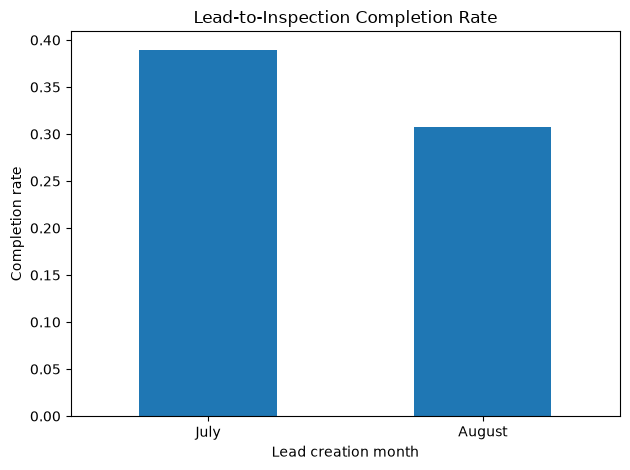

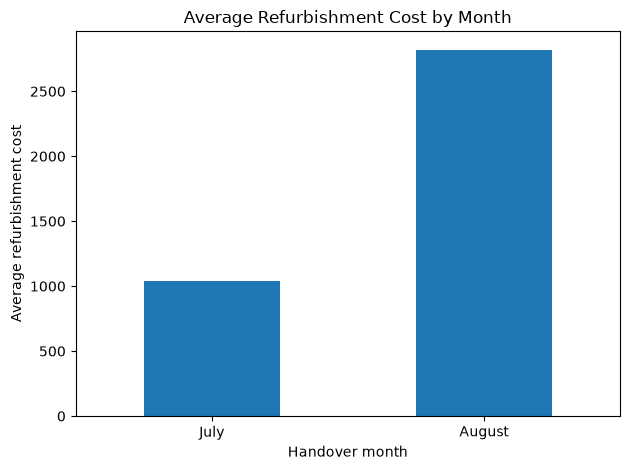

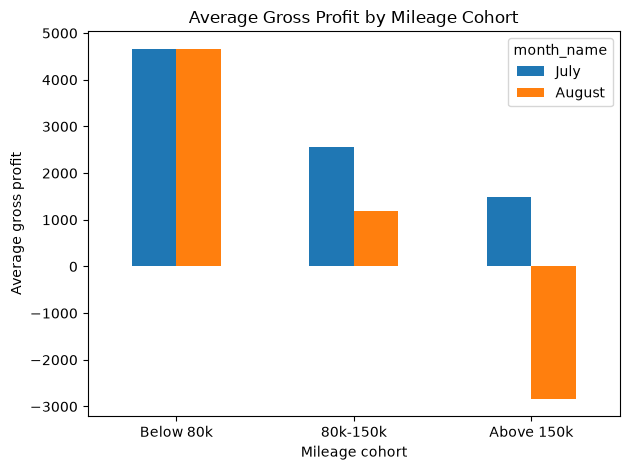

In [21]:
# 13. VISUALISATIONS
# Funnel conversion by month
funnel['completion_rate'].reindex(['July', 'August']).plot(kind='bar', title='Lead-to-Inspection Completion Rate')
plt.ylabel('Completion rate')
plt.xlabel('Lead creation month')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Average refurbishment cost by month
unit_economics['average_refurb_cost'].reindex(['July', 'August']).plot(kind='bar', title='Average Refurbishment Cost by Month')
plt.ylabel('Average refurbishment cost')
plt.xlabel('Handover month')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Average GP by mileage cohort and month
mileage_gp = cohort.groupby(['mileage_cohort', 'month_name'], observed=True)['GP'].mean().unstack()
mileage_gp.reindex(columns=['July', 'August']).plot(kind='bar', title='Average Gross Profit by Mileage Cohort')
plt.ylabel('Average gross profit')
plt.xlabel('Mileage cohort')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [22]:
# 14. EXPORT CLEANED DATA AND ANALYSIS OUTPUTS
transactions.to_csv('cleaned_transactions.csv', index=False)
leads.drop(columns=['lead_month', 'month_name'], errors='ignore').to_csv('cleaned_sourcing_leads.csv', index=False)
combined.to_csv('merged_cleaned_dataset.csv', index=False)
funnel.to_csv('funnel_analysis.csv')
channel_rates.to_csv('channel_funnel_analysis.csv')
unit_economics.to_csv('unit_economics.csv')
print('\nAnalysis complete. CSV outputs have been saved in the current folder.')


Analysis complete. CSV outputs have been saved in the current folder.
